# Laporan Praktikum — Preprocessing Teks Ulasan E-Commerce Bahasa Indonesia

| | |
|---|---|
| **Mata kuliah** | Natural Language Processing (Pemrosesan Bahasa Alami) |
| **Nama** | Hafiz Syauqi |
| **NIM** | 20146071 |
| **Dataset** | [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment) |
| **Repository GitHub** | https://github.com/hafiz-syq/tugas-nlp-sentimen-ecommerce |
| **Tanggal** | 17 November 2026 |

---

## 1. Tujuan Praktikum

1. Memuat dataset ulasan *e-commerce* berbahasa Indonesia dan menampilkan informasinya: jumlah
   data, kolom, serta distribusi label sentimen.
2. Menerapkan lima tahap *preprocessing* teks: **case folding**, **cleaning**, **tokenisasi**,
   **stopword removal**, dan **stemming**.
3. Menampilkan 10 contoh teks sebelum dan sesudah *preprocessing*.
4. Menjelaskan pengaruh *preprocessing* terhadap kualitas data teks berdasar angka hasil
   pengukuran pada korpus, bukan berdasar asumsi.

Seluruh angka pada laporan dicetak oleh kode — tidak ada nilai yang ditulis manual — sehingga isi
laporan dijamin sama dengan hasil eksekusi notebook.

## 2. Persiapan Pustaka

Pustaka yang dipakai: `pandas` (manipulasi tabel), `nltk` (tokenisasi dan daftar *stopword* bahasa
Indonesia), `Sastrawi` (*stemmer* bahasa Indonesia berbasis kamus), dan `matplotlib` (grafik).
Dataset dibaca dari salinan lokal pada folder `data/` supaya notebook dapat dijalankan ulang tanpa
terhubung ke Hugging Face.

In [1]:
import json
import math
import re
import time
import unicodedata
from collections import Counter
from html import unescape
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from IPython.display import display, HTML

try:
    from sastrawi.stemmer.stemmer_factory import StemmerFactory
except ImportError:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

try:
    nltk.data.find("corpora/stopwords")
except LookupError:
    nltk.download("stopwords", quiet=True)

STOPWORDS_ID = set(stopwords.words("indonesian"))
TOKENIZER = RegexpTokenizer(r"[a-z]+")
stemmer = StemmerFactory().create_stemmer()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", None)

print("Jumlah stopword bahasa Indonesia (NLTK):", len(STOPWORDS_ID))
print("Cek stemmer:", "membaca ->", stemmer.stem("membaca"), "| pengiriman ->", stemmer.stem("pengiriman"))

Jumlah stopword bahasa Indonesia (NLTK): 757
Cek stemmer: membaca -> baca | pengiriman -> kirim


## 3. Informasi Dataset

### 3.1 Memuat dataset

Dataset ini berisi 11.606 ulasan produk dari berbagai *brand* dan produk Indonesia pada beberapa
*marketplace* (Shopee, Tokopedia, Lazada, Bukalapak, Blibli, Zalora). Label `sentimen` bernilai
**1 = positif** dan **0 = negatif**. Kolom `translate` adalah terjemahan bahasa Inggris dari
`review` dan **tidak dipakai** dalam praktikum ini.

In [2]:
DATA_PATH = Path("data/labeledReview.datasetFix.json")
df = pd.DataFrame(json.loads(DATA_PATH.read_text(encoding="utf-8")))

print(f"Jumlah data : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Kolom       : {list(df.columns)}")
display(df.head(5))

Jumlah data : 11,606 baris x 3 kolom
Kolom       : ['review', 'sentimen', 'translate']


,review,sentimen,translate
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,0,"sound and mic satisfied. I only ordered the one that was on and I made sure that it clicked again, but the one that came didn't turn on"
1,Good. Mudah-mudahan awet. Makasih,1,good. hopefully durable. Thanks
2,"kondisi dus robek2, tolong di perhatikan lagi",0,"the condition of the box is torn, please pay attention again"
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,0,"product quality is good. affordable prices and very fast delivery. I've already ordered here, it's okay, but unfortunately, if you make a gift, you can't bring it with a greeting card or wrap it in gift paper :("
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",0,"overall is good, the buttons all work, but the packaging is lacking because it's dented and torn a little"


### 3.2 Kolom, tipe data, dan kelengkapan data

`info()` menampilkan tipe data dan jumlah nilai terisi tiap kolom, lalu dirangkum dalam tabel.

In [3]:
df.info()
print("\nJumlah nilai kosong (missing) per kolom:")
print(df.isna().sum().to_string())

<class 'pandas.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     11606 non-null  str  
 1   sentimen   11606 non-null  int64
 2   translate  11606 non-null  str  
dtypes: int64(1), str(2)
memory usage: 272.1 KB

Jumlah nilai kosong (missing) per kolom:
review       0
sentimen     0
translate    0


In [4]:
def describe_column(series):
    panjang = series.dropna().astype(str).str.len()
    return {
        "tipe data": str(series.dtype),
        "terisi": f"{series.notna().sum():,}",
        "kosong": f"{series.isna().sum():,}",
        "nilai unik": f"{series.nunique():,}",
        "panjang min": f"{panjang.min():,} karakter",
        "panjang maks": f"{panjang.max():,} karakter",
    }


display(pd.DataFrame({col: describe_column(df[col]) for col in df.columns}).T)

dup_rev = int(df.duplicated(subset=["review"]).sum())
print(f"\nBaris yang review-nya sama persis dengan baris lain : {dup_rev:,}")
print("Tiga ulasan yang paling sering berulang:")
display(df["review"].value_counts().head(3).to_frame("kemunculan"))

,tipe data,terisi,kosong,nilai unik,panjang min,panjang maks
review,str,"11,606",0,"11,599",1 karakter,"1,668 karakter"
sentimen,int64,"11,606",0,2,1 karakter,1 karakter
translate,str,"11,606",0,"11,584",1 karakter,"1,736 karakter"



Baris yang review-nya sama persis dengan baris lain : 7
Tiga ulasan yang paling sering berulang:


,kemunculan
review,
sesuai pesanan,2
pengiriman lumayan cepat,2
Alhamdulillah aman,2


### 3.3 Distribusi label sentimen

,label,nama,jumlah,persentase
0,0,Negatif,5803,50.0
1,1,Positif,5803,50.0


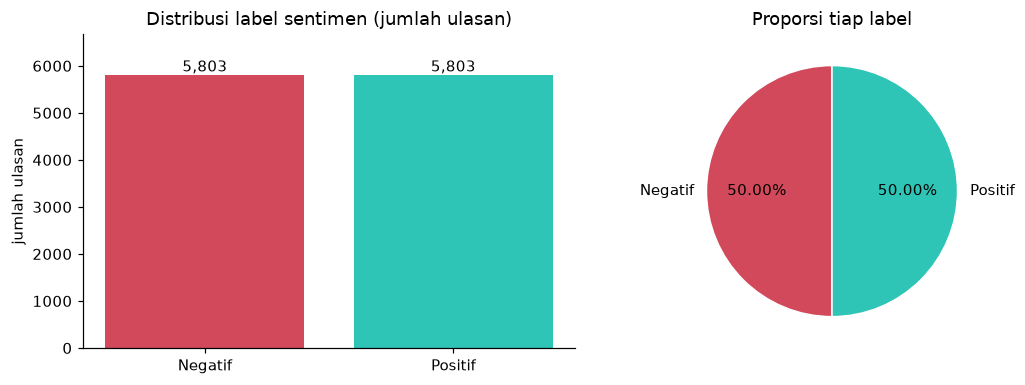

Rasio negatif : positif = 5,803 : 5,803  (dataset seimbang / balanced).
Panjang ulasan: rata-rata 103.6, median 78, maksimum 1,668 karakter.


In [5]:
LABEL_NAMES = {0: "Negatif", 1: "Positif"}
dist = df["sentimen"].value_counts().sort_index()
dist_df = pd.DataFrame(
    {
        "label": dist.index,
        "nama": dist.index.map(LABEL_NAMES),
        "jumlah": dist.values,
        "persentase": (dist.values / len(df) * 100).round(2),
    }
)
display(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
colors = ["#d1495b", "#2ec4b6"]
bars = axes[0].bar(dist_df["nama"], dist_df["jumlah"], color=colors)
axes[0].set_title("Distribusi label sentimen (jumlah ulasan)")
axes[0].set_ylabel("jumlah ulasan")
axes[0].set_ylim(0, dist_df["jumlah"].max() * 1.15)
for bar, val in zip(bars, dist_df["jumlah"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,}", ha="center", va="bottom")

axes[1].pie(
    dist_df["jumlah"],
    labels=dist_df["nama"],
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
axes[1].set_title("Proporsi tiap label")
plt.tight_layout()
plt.show()

print(f"Rasio negatif : positif = {dist.loc[0]:,} : {dist.loc[1]:,}  (dataset seimbang / balanced).")
print(f"Panjang ulasan: rata-rata {df['review'].str.len().mean():.1f}, "
      f"median {df['review'].str.len().median():.0f}, "
      f"maksimum {df['review'].str.len().max():,} karakter.")

Distribusinya **seimbang**, sehingga model klasifikasi di atasnya tidak condong ke salah satu kelas
dan akurasi menjadi metrik yang sah untuk dipakai. Tipe `sentimen` tercatat sebagai `int64` karena
format JSON menyimpannya sebagai angka; saat pemodelan, nilai ini diperlakukan sebagai kategori,
bukan sebagai besaran numerik.

### 3.4 Profil teks mentah

Sebelum menentukan aturan pembersihan, dihitung dulu berapa banyak ulasan yang benar-benar memuat
unsur yang akan dihapus. Profil ini yang menjadi dasar aturan pada bagian 4.2 — unsur yang hampir
tidak ada di data tidak perlu diberi perlakuan khusus.

In [6]:
POLA_TEKS = {
    "huruf kapital (butuh case folding)": r"[A-Z]",
    "tanda baca / karakter khusus": r"[^A-Za-z0-9\s]",
    "angka": r"\d",
    "sebut harga atau rating (rp, bintang n)": r"(?:rp\.?\s|bintang)",
    "entitas HTML hasil scraping (&amp;, &#34;, dsb.)": r"&(?:[a-zA-Z#0-9]{2,7});",
    "URL sungguhan (http:// atau www.)": r"(?:https?://|\bwww\.)",
    "penyebutan akun / hashtag": r"[@#]\w+",
    "karakter non-ASCII (emoji dsb.)": r"[^\x00-\x7f]",
}

profil = pd.DataFrame(
    {
        nama: int(sum(bool(re.search(pola, str(t), re.IGNORECASE)) for t in df["review"]))
        for nama, pola in POLA_TEKS.items()
    },
    index=["jumlah ulasan"],
).T
profil["persentase"] = (profil["jumlah ulasan"] / len(df) * 100).round(2)
profil["jumlah ulasan"] = profil["jumlah ulasan"].map("{:,}".format)
display(profil)

satu_kata = df["review"].astype(str).str.split().map(len) == 1
kosong = df["review"].astype(str).str.strip() == ""
print(f"Ulasan kosong total                 : {int(kosong.sum()):,}")
print(f"Ulasan yang hanya terdiri 1 kata    : {int(satu_kata.sum()):,} ({satu_kata.mean() * 100:.2f} %)")

,jumlah ulasan,persentase
huruf kapital (butuh case folding),"11,603",99.97
tanda baca / karakter khusus,"9,415",81.12
angka,"2,304",19.85
"sebut harga atau rating (rp, bintang n)",296,2.55
"entitas HTML hasil scraping (&amp;, &#34;, dsb.)",188,1.62
URL sungguhan (http:// atau www.),1,0.01
penyebutan akun / hashtag,82,0.71
karakter non-ASCII (emoji dsb.),"1,876",16.16


Ulasan kosong total                 : 0
Ulasan yang hanya terdiri 1 kata    : 108 (0.93 %)


Yang menonjol: hampir semua ulasan memakai huruf kapital dan tanda baca, cukup banyak yang
berisi angka (harga, jumlah, rating), sebagian membawa emoji, dan ada pula yang masih berupa
entitas HTML (`&amp;`, `&#34;`, `&#39;`) karena teksnya hasil *scraping* — entitas ini dibuka
lebih dulu (`html.unescape`) supaya tidak menyisakan residu berupa kata tak bermakna seperti
`amp`, `lt`, dan `gt` di hasil tokenisasi. Sebaliknya, URL sungguhan hampir tidak ada di dataset
ini, jadi aturan penghapusannya tetap ditulis (karena diminta dan tidak berbahaya) tetapi
sumbangannya kecil.
Ada juga sejumlah ulasan yang hanya berisi satu kata; kelompok ini perlu dipantau karena bisa
hilang seluruh isinya setelah *stopword removal*.

## 4. Tahapan Preprocessing Teks

Kelima tahap dijalankan berurutan. Urutan ini penting: *case folding* dan *cleaning* bekerja pada
level **string**, sedangkan tokenisasi, *stopword removal*, dan *stemming* bekerja pada level
**token** (setelah teks dipecah).

```
teks asli -> [1] case folding -> [2] cleaning -> [3] tokenisasi -> [4] stopword removal -> [5] stemming
```

### 4.1 Case folding

Menyeragamkan semua huruf menjadi kecil. Tanpa tahap ini, `"Bagus"`, `"bagus"`, dan `"BAGUS"`
dihitung sebagai tiga kata berbeda sehingga kosakata membengkak dan kata yang sama tidak pernah
bertemu pada fitur yang sama.

In [7]:
def case_folding(text):
    return str(text).lower()


contoh = df["review"].iloc[0]
print("Sebelum :", contoh)
print("Sesudah :", case_folding(contoh))

Sebelum : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Sesudah : suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala


### 4.2 Cleaning

Menghapus unsur yang tidak membawa makna sentimen: entitas HTML hasil *scraping*, URL, penyebutan
akun/*hashtag*, angka (harga dan jumlah), tanda baca, emoji, dan karakter khusus. Huruf non-ASCII
yang punya padanan (mis. `é`) dinormalisasi lebih dulu agar tetap terbaca sebagai huruf biasa.
Setelah tahap ini, yang tersisa hanya huruf a–z dan spasi.

In [8]:
RE_URL = re.compile(r"(?:https?://|\bwww\.)\S+")
RE_MENTION = re.compile(r"[@#]\w+")
RE_PRICE = re.compile(r"(?:rp\s*)?[\d.,]+\s*(?:rb|jt|ribu|juta)?|\b(?:idr|rp)\b")
RE_NUMBER = re.compile(r"\d+(?:[.,]\d+)*")
RE_NON_ALPHA = re.compile(r"[^a-z\s]")
RE_SPACE = re.compile(r"\s+")


def clean_text(text):
    text = unescape(str(text))
    text = case_folding(text)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    for pola in (RE_URL, RE_MENTION, RE_PRICE, RE_NUMBER, RE_NON_ALPHA):
        text = pola.sub(" ", text)
    return RE_SPACE.sub(" ", text).strip()


print("=== 5 ulasan pertama ===")
for sample in df["review"].head(5):
    print("Sebelum :", sample)
    print("Sesudah :", clean_text(sample))
    print("-" * 100)

print("=== kasus khusus: entitas HTML, emoji, dan URL ===")
kasus = df.loc[
    df["review"].astype(str).str.contains(r"&(?:[a-zA-Z#0-9]{2,7});|[^\x00-\x7f]|https?://", regex=True, na=False),
    "review",
].head(6)
for sample in kasus:
    print("Sebelum :", sample)
    print("Sesudah :", clean_text(sample))
    print("-" * 100)

print("=== kenapa html.unescape diperlukan ===")
for sample in [t for t in kasus if "&" in str(t)][:3]:
    mentah = str(sample)
    posisi = mentah.find("&")
    tanpa = re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", case_folding(mentah))).strip()
    dengan = clean_text(mentah)
    beda = sorted(set(TOKENIZER.tokenize(tanpa)) - set(TOKENIZER.tokenize(dengan)))
    print(f"  potongan asli                    : ...{mentah[max(0, posisi - 25):posisi + 25].strip()}...")
    print(f"  tanpa unescape -> kata palsu yang tersisa: {beda}")
    print("  dengan unescape -> kata-kata itu sudah hilang sebelum tokenisasi")
    print("-" * 100)

=== 5 ulasan pertama ===
Sebelum : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Sesudah : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
----------------------------------------------------------------------------------------------------
Sebelum : Good. Mudah-mudahan awet. Makasih 
Sesudah : good mudah mudahan awet makasih
----------------------------------------------------------------------------------------------------
Sebelum : kondisi dus robek2, tolong di perhatikan lagi
Sesudah : kondisi dus robek tolong di perhatikan lagi
----------------------------------------------------------------------------------------------------
Sebelum : Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(
Sesudah : kualitas produk baik harga ter

Harga (`Rp120.000`, `15rb`) dan angka jumlah (`5`) ikut terhapus, sedangkan kata di sekitarnya
seperti `bintang` dibiarkan — kata itu masih bisa menjadi petunjuk sentimen. Bila jumlah bintang
nantinya dipakai sebagai fitur model, nilainya harus diambil ke kolom terpisah **sebelum** tahap
pembersihan ini, bukan sesudahnya (bagian 6.1 mengukur konsekuensi penghapusan angka).

Perbandingan di atas memperlihatkan alasan langkah `unescape`: tanpa tahap itu, nama entitas
`&amp;` dan `&lt;...&gt;` tertinggal sebagai kata palsu (`amp`, `lt`, `gt`) yang akan ikut
terhitung sebagai fitur.

### 4.3 Tokenisasi

Teks bersih dipecah menjadi satuan kata (*token*). Karena pada titik ini teks hanya menyisakan
huruf a–z dan spasi, dipakai `nltk.tokenize.RegexpTokenizer` berpola `[a-z]+`: hasilnya sama dengan
pemecahan per kata, tetapi tidak perlu mengunduh paket model pen-*tokenize* dan tidak membawa
aturan bahasa Inggris (misalnya pemisahan apostrof) yang sudah tidak relevan. Token satu huruf
(sisa singkatan seperti `y`, `x`) dibuang karena tidak membawa makna.

In [9]:
def tokenize(text):
    return [tok for tok in TOKENIZER.tokenize(clean_text(text)) if len(tok) > 1]


contoh_tk = contoh  # ulasan yang sama dengan contoh pada bagian 4.1, agar perubahannya bisa diikuti
print("Teks asli   :", contoh_tk)
print("Teks bersih :", clean_text(contoh_tk))
print("Token       :", tokenize(contoh_tk))
print("Jumlah token:", len(tokenize(contoh_tk)))

Teks asli   : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Teks bersih : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Token       : ['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']
Jumlah token: 22


### 4.4 Stopword removal

Kata yang frekuensinya tinggi tetapi tidak membedakan sentimen (`yang`, `di`, `dan`, `untuk`,
`saya`) dibuang memakai daftar *stopword* bahasa Indonesia dari NLTK.

In [10]:
def remove_stopwords(tokens):
    return [tok for tok in tokens if tok not in STOPWORDS_ID]


tokens_awal = tokenize(contoh_tk)
tokens_sisa = remove_stopwords(tokens_awal)
print("Dibuang :", [tok for tok in tokens_awal if tok in STOPWORDS_ID])
print("Sisa    :", tokens_sisa)

Dibuang : ['dan', 'hanya', 'saya', 'dan', 'sudah', 'datang']
Sisa    : ['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']


### 4.5 Stemming

Mengubah kata berimbuhan menjadi bentuk dasar (akar kata) memakai **Sastrawi**. Karena Sastrawi
bekerja dengan kamus kata dasar bahasa Indonesia, kata di luar kamus — termasuk kata tidak baku
seperti `ga` dan `bgt` — dikembalikan apa adanya. Itu perilaku wajar, bukan kesalahan program.

In [11]:
def stem(tokens):
    return [stemmer.stem(tok) for tok in tokens]


for kata in ["mengirim", "pengiriman", "kirim", "memuaskan", "pembelian", "kecewanya", "terbaik", "speed", "bgt"]:
    print(f"{kata:>12} -> {stemmer.stem(kata)}")

    mengirim -> kirim
  pengiriman -> kirim
       kirim -> kirim
   memuaskan -> muas


   pembelian -> beli
   kecewanya -> kecewa
     terbaik -> baik
       speed -> speed
         bgt -> bgt


### 4.6 Rangkaian lengkap (pipeline)

Kelima tahap dirangkai dalam satu fungsi `preprocess()`. Dengan `keep_trace=True` fungsi ini
mengembalikan hasil tiap tahap, sehingga perubahan tiap tahap bisa diaudit — bukan hanya hasil
akhirnya.

In [12]:
def preprocess(text, keep_trace=False):
    folded = case_folding(text)
    cleaned = clean_text(text)
    tokens = tokenize(cleaned)
    content = remove_stopwords(tokens)
    stemmed = stem(content)
    if keep_trace:
        return {
            "asli": str(text),
            "case_folding": folded,
            "cleaning": cleaned,
            "tokenisasi": tokens,
            "stopword_removal": content,
            "stemming": stemmed,
            "hasil": " ".join(stemmed),
        }
    return " ".join(stemmed)


t0 = time.time()
trace = [preprocess(review, keep_trace=True) for review in df["review"]]
elapsed = time.time() - t0

df["clean"] = [t["cleaning"] for t in trace]
df["tokens"] = [t["stemming"] for t in trace]
df["hasil"] = [" ".join(t) for t in df["tokens"]]
df["n_token_asli"] = [len(t["tokenisasi"]) for t in trace]
df["n_token_final"] = [len(t) for t in df["tokens"]]

print(f"Seluruh korpus ({len(df):,} ulasan) selesai diproses dalam {elapsed:.1f} detik.")
df[["review", "clean", "hasil"]].head(3)

Seluruh korpus (11,606 ulasan) selesai diproses dalam 490.4 detik.


,review,clean,hasil
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudahan awet makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong di perhatikan lagi,kondisi dus robek tolong perhati


## 5. Sepuluh Contoh Teks Sebelum dan Sesudah Preprocessing

Sampel diambil dengan `random_state=7` supaya daftarnya sama setiap kali notebook dijalankan.

In [13]:
sample_idx = df.sample(n=10, random_state=7).index
show = (
    df.loc[sample_idx, ["review", "hasil", "n_token_asli", "n_token_final", "sentimen"]]
    .assign(sentimen=lambda d: d["sentimen"].map(LABEL_NAMES))
    .reset_index(drop=True)
    .rename(columns={
        "review": "Teks asli",
        "hasil": "Sesudah preprocessing (hasil akhir)",
        "n_token_asli": "token awal",
        "n_token_final": "token akhir",
        "sentimen": "label",
    })
)
display(HTML(show.to_html(border=1, justify="center", classes="table")))

,Teks asli,Sesudah preprocessing (hasil akhir),token awal,token akhir,label
0,liat bintangnya gak nyesel blanja disini,liat bintang gak nyesel blanja,6,5,Negatif
1,sesuai deskripsi and suara bagus,sesuai deskripsi and suara bagus,5,5,Positif
2,"barang diterima baik, sesuai dengan pesanan, kemasan juga baik\nterimakasih\n",barang terima sesuai pesan kemas terimakasih,10,6,Positif
3,Barang baggus kakkk baranfnyaa ga ada yg cacattt next akan pesan lagi.,barang baggus kakkk baranfnyaa ga yg cacattt next pesan,12,9,Positif
4,kualitas lumayan.sesuai harga,kualitas lumayan sesuai harga,4,4,Positif
5,"Alhamdulillah udah sampe pesen tgl 10 , bagusss 🤩🤩",alhamdulillah udah sampe sen tgl bagusss,6,6,Positif
6,mantabhh,mantabhh,1,1,Positif
7,Fitur Terbaik:ok\nSepadan dengan Harga:ya,fitur baik ok padan harga ya,7,6,Positif
8,"Barang sudah di terima, tapi belum di cek performa nya seperti apa",barang terima cek performa nya,12,5,Positif
9,"sudah sampai dengan cepat, pesan langsung proses langsung kirim, kualitas mouse bagus",cepat pesan langsung proses langsung kirim kualitas mouse bagus,12,9,Positif


### 5.1 Jejak tiap tahap pada satu ulasan

Dari sepuluh sampel di atas, dipilih satu ulasan yang **kelima tahapnya terlihat mengubah teks**
supaya kontribusi tiap tahap tampak, bukan hanya hasil akhirnya. Kalau ulasan pertama kebetulan
sudah bersih, tahap 1-3 memang tidak mengubah apa pun — itu pun informasi, hanya saja kurang
berguna untuk menjelaskan peran tiap tahap.

In [14]:
def tiap_tahap_terlihat(idx):
    t = trace[df.index.get_loc(idx)]
    return (
        t["case_folding"] != t["asli"]
        and t["cleaning"] != t["case_folding"]
        and len(t["stopword_removal"]) < len(t["tokenisasi"])
        and t["stemming"] != t["stopword_removal"]
    )


trace_idx = next((i for i in sample_idx if tiap_tahap_terlihat(i)), sample_idx[0])
pick = trace[df.index.get_loc(trace_idx)]
rows = [
    ("0. teks asli", pick["asli"]),
    ("1. case folding", pick["case_folding"]),
    ("2. cleaning", pick["cleaning"]),
    ("3. tokenisasi", " ".join(pick["tokenisasi"])),
    ("4. stopword removal", " ".join(pick["stopword_removal"])),
    ("5. stemming", " ".join(pick["stemming"])),
]
trace_df = pd.DataFrame(rows, columns=["tahap", "hasil"])
trace_df["jumlah token"] = [len(str(h).split()) for h in trace_df["hasil"]]
display(HTML(trace_df.to_html(border=1, index=False, justify="left")))
print("Label ulasan ini:", LABEL_NAMES[df.loc[trace_idx, "sentimen"]])

tahap,hasil,jumlah token
0. teks asli,Fitur Terbaik:ok\nSepadan dengan Harga:ya,5
1. case folding,fitur terbaik:ok\nsepadan dengan harga:ya,5
2. cleaning,fitur terbaik ok sepadan dengan harga ya,7
3. tokenisasi,fitur terbaik ok sepadan dengan harga ya,7
4. stopword removal,fitur terbaik ok sepadan harga ya,6
5. stemming,fitur baik ok padan harga ya,6


Label ulasan ini: Positif


## 6. Pengaruh Preprocessing terhadap Kualitas Data Teks

Bagian ini mengukur dampaknya pada seluruh korpus. Kondisi "sebelum" dihitung dari teks asli yang
hanya dipecah berdasarkan spasi — jadi belum melewati satu tahap pun.

In [15]:
df["tokens_raw"] = [str(review).split() for review in df["review"]]
raw_all = Counter(tok for toks in df["tokens_raw"] for tok in toks)
fin_all = Counter(tok for toks in df["tokens"] for tok in toks)

# Token sesudah tokenisasi (sebelum stopword removal), per kelas label.
PRE_STOP = {label: Counter() for label in LABEL_NAMES}
for sent, tr in zip(df["sentimen"], trace):
    PRE_STOP[sent].update(tr["tokenisasi"])
pre_all = PRE_STOP[0] + PRE_STOP[1]
n_pre = sum(pre_all.values())


def ttr(counter):
    total = sum(counter.values())
    return len(counter) / total if total else float("nan")


n_raw, n_fin = int(df["tokens_raw"].map(len).sum()), int(df["n_token_final"].sum())
before = {
    "total token": n_raw,
    "kosakata unik (type)": len(raw_all),
    "type-token ratio (TTR)": ttr(raw_all),
    "rata-rata token per ulasan": n_raw / len(df),
    "rata-rata panjang teks (karakter)": df["review"].str.len().mean(),
}
after = {
    "total token": n_fin,
    "kosakata unik (type)": len(fin_all),
    "type-token ratio (TTR)": ttr(fin_all),
    "rata-rata token per ulasan": n_fin / len(df),
    "rata-rata panjang teks (karakter)": df["hasil"].str.len().mean(),
}
metrics = pd.DataFrame(
    {
        "sebelum preprocessing": pd.Series(before),
        "sesudah preprocessing": pd.Series(after),
    }
)
metrics["perubahan"] = metrics["sesudah preprocessing"] - metrics["sebelum preprocessing"]
metrics["berubah (%)"] = (metrics["perubahan"] / metrics["sebelum preprocessing"] * 100).round(1)
metrics = metrics.reset_index(names="metrik")
for col in ("sebelum preprocessing", "sesudah preprocessing"):
    metrics[col] = metrics[col].map(lambda v: f"{v:,.4f}".rstrip("0").rstrip("."))
metrics["perubahan"] = metrics["perubahan"].map(lambda v: f"{v:+,.4f}".rstrip("0").rstrip("."))
display(metrics)

n_stop = sum(c for tok, c in pre_all.items() if tok in STOPWORDS_ID)
print(f"Token hasil tokenisasi (sebelum stopword) : {n_pre:,}")
print(f"  terbuang karena stopword                : {n_stop:,} ({n_stop / n_pre * 100:.1f} % dari token hasil tokenisasi)")
print(f"Kosakata unik (split spasi -> hasil akhir): {len(raw_all):,} -> {len(fin_all):,} bentuk "
      f"({(1 - len(fin_all) / len(raw_all)) * 100:.1f} % lebih sedikit)")
print(f"Total token    (split spasi -> hasil akhir): {n_raw:,} -> {n_fin:,} "
      f"({(1 - n_fin / n_raw) * 100:.1f} % lebih sedikit)")

,metrik,sebelum preprocessing,sesudah preprocessing,perubahan,berubah (%)
0,total token,"182,871","129,701","-53,170",-29.1
1,kosakata unik (type),"26,205","10,063","-16,142",-61.6
2,type-token ratio (TTR),0.1433,0.0776,-0.0657,-45.9
3,rata-rata token per ulasan,15.7566,11.1753,-4.5813,-29.1
4,rata-rata panjang teks (karakter),103.572,67.2853,-36.2867,-35.0


Token hasil tokenisasi (sebelum stopword) : 181,199
  terbuang karena stopword                : 51,498 (28.4 % dari token hasil tokenisasi)
Kosakata unik (split spasi -> hasil akhir): 26,205 -> 10,063 bentuk (61.6 % lebih sedikit)
Total token    (split spasi -> hasil akhir): 182,871 -> 129,701 (29.1 % lebih sedikit)


In [16]:
KATA_BERMAKNA = ["lama", "tidak", "bisa", "susah", "sulit", "lambat", "cacat", "rusak", "bagus", "awet"]
informal = ["yg", "ga", "gak", "tp", "ngk", "bgt", "udh", "sy", "aj", "dlm"]

cek = pd.DataFrame(
    {
        "di daftar stopword NLTK": [kata in STOPWORDS_ID for kata in KATA_BERMAKNA + informal],
        "frekuensi di kelas negatif": [PRE_STOP[0].get(kata, 0) for kata in KATA_BERMAKNA + informal],
        "frekuensi di kelas positif": [PRE_STOP[1].get(kata, 0) for kata in KATA_BERMAKNA + informal],
        "masih ada di hasil akhir": [fin_all.get(kata, 0) > 0 for kata in KATA_BERMAKNA + informal],
    },
    index=KATA_BERMAKNA + informal,
)
cek.index.name = "kata"
display(cek)
print("10 kata pertama adalah kata yang membawa makna; 10 berikutnya bentuk informal yang sering dipakai di ulasan.")

,di daftar stopword NLTK,frekuensi di kelas negatif,frekuensi di kelas positif,masih ada di hasil akhir
kata,,,,
lama,True,1412,263,True
tidak,True,1217,216,True
bisa,True,836,276,True
susah,False,79,6,True
sulit,False,14,4,True
lambat,False,159,10,True
cacat,False,90,97,True
rusak,False,231,57,True
bagus,False,1264,1752,True


10 kata pertama adalah kata yang membawa makna; 10 berikutnya bentuk informal yang sering dipakai di ulasan.


In [17]:
dup_sebelum = int(df.duplicated(subset=["review"]).sum())
dup_sesudah = int(df.duplicated(subset=["hasil"]).sum())
print(f"Teks yang sama persis sebelum preprocessing : {dup_sebelum:,} baris")
print(f"Teks yang sama persis sesudah preprocessing : {dup_sesudah:,} baris")
print(f"Duplikat yang baru terlihat setelah preprocessing : {dup_sesudah - dup_sebelum:,} baris")

# Grup hasil akhir yang sama, tetapi teks aslinya berbeda-beda: inilah bukti bahwa
# preprocessing menyatukan ulasan yang selama ini dianggap berbeda.
grup = (
    df.groupby("hasil")
    .agg(ulasan_asli_berbeda=("review", "nunique"), jumlah_ulasan=("review", "size"))
    .query("jumlah_ulasan > 1 and ulasan_asli_berbeda > 1")
    .sort_values(["ulasan_asli_berbeda", "jumlah_ulasan"], ascending=False)
)
print(f"\nGrup hasil akhir yang sama tetapi aslinya berbeda: {len(grup):,} grup, "
      f"{int((grup['jumlah_ulasan'] - 1).sum()):,} baris di antaranya redundant")
display(grup.head(5).reset_index())

Teks yang sama persis sebelum preprocessing : 7 baris
Teks yang sama persis sesudah preprocessing : 215 baris
Duplikat yang baru terlihat setelah preprocessing : 208 baris

Grup hasil akhir yang sama tetapi aslinya berbeda: 101 grup, 210 baris di antaranya redundant


,hasil,ulasan_asli_berbeda,jumlah_ulasan
0,kirim,25,25
1,,20,20
2,mantap,9,9
3,barang bagus kirim,7,7
4,barang oke kirim,6,6


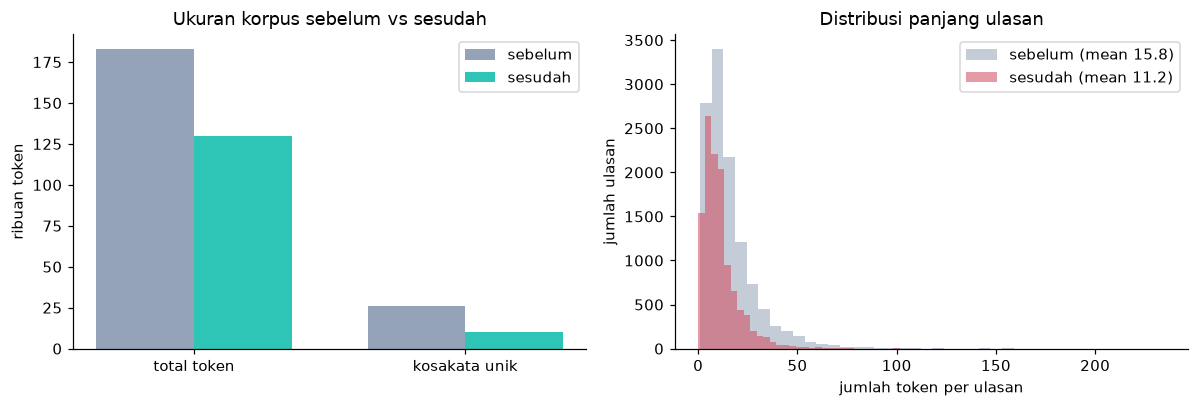

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = ["total token", "kosakata unik"]
idx = np.arange(len(x))
axes[0].bar(idx - 0.18, [n_raw / 1000, len(raw_all) / 1000], width=0.36, color="#94a3b8", label="sebelum")
axes[0].bar(idx + 0.18, [n_fin / 1000, len(fin_all) / 1000], width=0.36, color="#2ec4b6", label="sesudah")
axes[0].set_xticks(idx, x)
axes[0].set_ylabel("ribuan token")
axes[0].set_title("Ukuran korpus sebelum vs sesudah")
axes[0].legend()

len_before = df["tokens_raw"].map(len).to_numpy()
len_after = df["n_token_final"].to_numpy()
axes[1].hist(len_before, bins=40, alpha=0.55, color="#94a3b8", label=f"sebelum (mean {len_before.mean():.1f})")
axes[1].hist(len_after, bins=40, alpha=0.55, color="#d1495b", label=f"sesudah (mean {len_after.mean():.1f})")
axes[1].set_xlabel("jumlah token per ulasan")
axes[1].set_ylabel("jumlah ulasan")
axes[1].set_title("Distribusi panjang ulasan")
axes[1].legend()
plt.tight_layout()
plt.show()

In [19]:
def top_per_label(column, header, k=12):
    frames = []
    for label, name in LABEL_NAMES.items():
        cnt = Counter(tok for toks in df.loc[df["sentimen"] == label, column] for tok in toks)
        frames.append(pd.DataFrame(cnt.most_common(k), columns=[f"{name} — {header}", "frekuensi"]))
    return pd.concat(frames, axis=1)


print("SEBELUM preprocessing: didominasi stopword, tanda baca, dan variasi huruf besar-kecil")
display(top_per_label("tokens_raw", "token mentah"))

SEBELUM preprocessing: didominasi stopword, tanda baca, dan variasi huruf besar-kecil


,Negatif — token mentah,frekuensi,Positif — token mentah,frekuensi
0,di,2081,dan,1401
1,nya,1644,dengan,1322
2,barang,1364,barang,1097
3,dan,1261,bagus,831
4,ada,1227,sesuai,822
5,yg,1226,pengiriman,792
6,pengiriman,1203,di,739
7,tidak,1110,nya,720
8,lama,969,Barang,636
9,tapi,952,cepat,620


In [20]:
print("SESUDAH preprocessing: tanda baca, variasi huruf, dan kata umum hilang; urutan teratas "
      "bergeser ke kata benda/kejadian (kirim, barang, bagus, cepat) - tetapi masih ada sisa "
      "informal seperti 'nya', 'yg', 'ga', 'tp' yang dibahas di bagian 6.2")
display(top_per_label("tokens", "akar kata"))

SESUDAH preprocessing: tanda baca, variasi huruf, dan kata umum hilang; urutan teratas bergeser ke kata benda/kejadian (kirim, barang, bagus, cepat) - tetapi masih ada sisa informal seperti 'nya', 'yg', 'ga', 'tp' yang dibahas di bagian 6.2


,Negatif — akar kata,frekuensi,Positif — akar kata,frekuensi
0,kirim,2655,barang,2301
1,barang,2428,bagus,1757
2,nya,1929,kirim,1500
3,bagus,1276,cepat,1345
4,yg,1268,sesuai,1061
5,ga,918,harga,861
6,gak,640,nya,860
7,sesuai,623,moga,703
8,respon,614,kualitas,652
9,beli,576,mantap,651


Frekuensi tertinggi saja tidak membuktikan kelas terpisah: kata populer (`barang`, `kirim`, `bagus`)
muncul di kedua sisi. Yang menjawab pertanyaan pemisahan kelas adalah kata yang **porsinya berbeda**
antara kedua kelas. Tabel berikut membandingkan frekuensi tiap akar kata di kelas negatif dan positif
(minimum 80 kemunculan), lalu mengambil kata dengan rasio paling condong ke salah satu kelas.

In [21]:
def kata_khas(label, k=12, minimum=80):
    # Akar kata yang paling condong muncul di kelas `label` dibanding kelas lawannya.
    other = 1 - label
    cnt = Counter(tok for toks in df.loc[df["sentimen"] == label, "tokens"] for tok in toks)
    cnt_o = Counter(tok for toks in df.loc[df["sentimen"] == other, "tokens"] for tok in toks)
    skor = {w: math.log((c + 1) / (cnt_o.get(w, 0) + 1)) for w, c in cnt.items() if c >= minimum}
    return pd.DataFrame(sorted(skor.items(), key=lambda kv: -kv[1])[:k],
                        columns=[f"kata khas {LABEL_NAMES[label]}", "rasio log (kelas ini : kelas lain)"])


khas = pd.concat([kata_khas(0), kata_khas(1)], axis=1)
display(khas)
tumpang = set(khas.iloc[:, 0].dropna()) & set(khas.iloc[:, 2].dropna())
print("Rasio log > 0 berarti kata itu lebih sering muncul di kelas tersebut daripada di kelas "
      "lawan; makin besar angkanya, makin kuat kata itu menjadi pembeda.")
print(f"Kata yang masuk kedua daftar sekaligus: {len(tumpang)} -> {sorted(tumpang)}")

,kata khas Negatif,rasio log (kelas ini : kelas lain),kata khas Positif,rasio log (kelas ini : kelas lain)
0,buruk,3.979682,fiturnya,2.614960
1,status,3.761200,top,1.964372
2,tolong,3.394508,sukses,1.937942
3,slow,3.295837,elegan,1.775499
4,komplain,3.178054,desain,1.725802
5,mati,3.157000,kokoh,1.633154
6,jelek,3.044522,resolusi,1.522427
7,balas,2.988564,packaging,1.450010
8,parah,2.856470,rapi,1.430746
9,chat,2.856470,pokok,1.425009


Rasio log > 0 berarti kata itu lebih sering muncul di kelas tersebut daripada di kelas lawan; makin besar angkanya, makin kuat kata itu menjadi pembeda.
Kata yang masuk kedua daftar sekaligus: 0 -> []


### 6.1 Apa yang hilang bersama *noise*

Penghapusan angka tidak selalu netral. Pada ulasan penjualan, angka sering membawa makna
(`2 hari`, `bintang 1`, `3 kali`). Tabel berikut menghitung dan memperlihatkan ulasan yang
kehilangan keterangan semacam itu.

In [22]:
POLA_SATUAN = r"\d+\s*(?:hari|bulan|kali|tahun|bintang|x)\b"
terdampak = df.loc[df["review"].astype(str).str.contains(POLA_SATUAN, case=False), ["review", "hasil"]]
angka_hilang = int(sum(bool(re.search(r"\d", str(t))) and not bool(re.search(r"\d", h))
                      for t, h in zip(df["review"], df["hasil"])))

print(f"Ulasan yang memuat angka              : {int(df['review'].astype(str).str.contains(r'\d').sum()):,}")
print(f"Ulasan yang angkanya habis terhapus   : {angka_hilang:,}")
print(f"Ulasan yang angkanya terkait satuan   : {len(terdampak):,} -> contoh 5 teratas berikut")
display(terdampak.head(5).reset_index(drop=True))

Ulasan yang memuat angka              : 2,304
Ulasan yang angkanya habis terhapus   : 2,304
Ulasan yang angkanya terkait satuan   : 605 -> contoh 5 teratas berikut


,review,hasil
0,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk harga jangkau kirim cepet banget udh order oke tp sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado
1,Pengiriman sangat cepat cuma 2 hari . barang berpungsi sangat baik . cuma packingnya aja yg kurang aman . untungnya semua barangnya gak ada yg cacat sedikitpun 👍🏻,kirim cepat barang pungsi packingnya aja yg aman untung barang gak yg cacat sedikit
2,be a smart buyer. ku minta kirim hari itu langsung dikirim. besok nya lsg nyampe. dan sudah cek kualitas dan orisinil nya. 100% bagus dan ori. udah ke2 x beli. mantap pokoknya?,be smart buyer ku kirim langsung kirim besok nya lsg nyampe cek kualitas orisinil nya bagus ori udah beli mantap pokok
3,"Pengiriman agak lama, karna terkendala ppkm\nPdhl sesama jkt, total 3hari sampai diterima. \nMungkin kedepannya ditingkatkan lagi untuk proses pengiriman\nUntuk barang ok",kirim karna kendala ppkm pdhl jkt total terima depan tingkat proses kirim barang ok
4,"sesuai deskripsi,batere setelah diCas kedua kali kuatnya tidak main2... anak main sampai puas 👍👍👍\nhanya pas setelah beberapa waktu lcd pecah dan saya hanya tanya tempat servis terdekat sudah tidak respon terus 2 hari kemudian hilang 😂😂😂(type penjual sekali laku raib).\nwalau bukan tanggung jawabmu masa kasih info aja tidak mau?!",sesuai deskripsi batere cas kali kuat main anak main puas pas lcd pecah servis dekat respon hilang type jual laku raib tanggung jawab kasih info aja


Begitu pula dengan negasi. `tidak`, `bukan`, `belum`, dan `tanpa` termasuk kata umum, tetapi
fungsinya membalik makna — tabel berikut mengecek mana di antaranya yang ada di daftar *stopword*
NLTK sehingga ikut terbuang, dan seberapa banyak sisa bentuknya di hasil akhir.

In [23]:
KATA_TERBILANG = ["tidak", "bukan", "belum", "tanpa", "jangan", "sangat"]
jejak = pd.DataFrame(
    {
        "di daftar stopword NLTK": [kata in STOPWORDS_ID for kata in KATA_TERBILANG],
        "frekuensi sebelum stopword removal": [pre_all.get(kata, 0) for kata in KATA_TERBILANG],
        "sisa di hasil akhir": [fin_all.get(kata, 0) for kata in KATA_TERBILANG],
    },
    index=KATA_TERBILANG,
)
jejak.index.name = "kata"
display(jejak)
sisa_negasi = sum(fin_all.get(kata, 0) for kata in KATA_TERBILANG)
negasi_set = set(KATA_TERBILANG)
asal_sisa = Counter()
for t in trace:
    if negasi_set.intersection(t["stemming"]):
        for tok in t["stopword_removal"]:
            if stemmer.stem(tok) in negasi_set:
                asal_sisa[tok] += 1
print(f"Total sisa keenam kata itu di hasil akhir: {sisa_negasi:,} token.")
print("Bentuk asal yang menghasilkan sisa itu:", dict(asal_sisa))
if asal_sisa:
    contoh_bentuk = max(asal_sisa, key=asal_sisa.get)
    print(f"Contoh: '{contoh_bentuk}' tidak ada di daftar stopword sehingga tidak dibuang, lalu "
          "stemming mengembalikannya menjadi kata negasi. Sisa seperti ini bukan bug, tetapi "
          "menunjukkan bahwa penghapusan negasi tidak tuntas hanya dengan daftar kata umum.")
else:
    print("Pada korpus ini tidak ada sisa sama sekali: seluruh kata negasi hilang bersama stopword, "
          "yang berarti informasi negasinya ikut terhapus dari fitur.")

,di daftar stopword NLTK,frekuensi sebelum stopword removal,sisa di hasil akhir
kata,,,
tidak,True,1433,2
bukan,True,125,0
belum,True,355,1
tanpa,True,197,0
jangan,True,125,0
sangat,True,1021,0


Total sisa keenam kata itu di hasil akhir: 3 token.
Bentuk asal yang menghasilkan sisa itu: {'tidaknya': 2, 'belumnya': 1}
Contoh: 'tidaknya' tidak ada di daftar stopword sehingga tidak dibuang, lalu stemming mengembalikannya menjadi kata negasi. Sisa seperti ini bukan bug, tetapi menunjukkan bahwa penghapusan negasi tidak tuntas hanya dengan daftar kata umum.


### 6.2 Interpretasi

**Dampak positif.**

- **Redundansi berkurang, tanpa mengorbankan sebagian besar isi.** Pertanyaan pentingnya bukan
  "berapa banyak yang dibuang", melainkan "apa yang dibuang". Angka tercetak di sel di atas: dari
  token hasil tokenisasi, yang terbuang karena *stopword* kurang dari sepertiganya, sedangkan
  sisanya hilang karena tahap lain (angka/tanda baca yang memang bukan kata, dan penggabungan
  imbuhan oleh *stemmer*). Rata-rata token per ulasan turun dari sekitar 16 ke sekitar 11 kata inti —
  fitur yang masuk ke model lebih pendek, lebih padat, dan lebih murah diproses.
- **Kosakata menyempit jauh lebih cepat daripada teksnya.** Kolom "berubah (%)" pada tabel metrik
  membandingkan keduanya: jumlah *bentuk unik* menyusut beberapa kali lipat lebih dalam daripada
  jumlah *token*. Artinya `pengiriman`, `mengirim`, dan `kirim` tidak lagi menempati tiga kolom fitur
  terpisah — bukti frekuensi untuk satu konsep terkumpul pada satu akar kata, sehingga *sparsity*
  berkurang dan tiap fitur punya lebih banyak contoh untuk dipelajari.
- **Teks menjadi seragam.** Huruf kecil, tanpa URL/angka/emoji/tanda baca/entitas HTML membuat dua
  ulasan yang bermakna sama menjadi identik secara *string*. Buktinya terukur pada sel duplikat di
  atas: jumlah baris yang sama persis naik setelah *preprocessing*, dan tabel grup di bawahnya
  menunjukkan baris-baris baru itu memang datang dari teks asli yang berbeda-beda (kolom
  `ulasan_asli_berbeda` > 1) — bukan dari data yang sejak awal duplikat. Tanpa penyeragaman itu,
  `Barang` dan `barang` dihitung sebagai dua fitur berbeda dan penghitungan frekuensi maupun
  *vectorization* (BoW/TF-IDF) tidak valid.
- **Sinyal pemisah kelas justru lebih terlihat.** Frekuensi mentah saja tidak cukup, karena kata
  populer (`barang`, `kirim`, `bagus`) muncul di kedua kelas. Karena itu bagian 6 menampilkan dua
  hal berbeda. Pertama, kata tersering bergeser dari kata fungsi (`di`, `dan`, `dengan`, `ada`) ke
  kata bermakna (`kirim`, `barang`, `bagus`, `cepat`). Kedua, tabel "kata khas" menyusun kata
  berdasar rasio frekuensi antar kelas, dan hasilnya dua daftar yang tidak beririsan sama sekali:
  sisi negatif diisi `buruk`, `komplain`, `mati`, `lambat`, `jelek`, `parah`; sisi positif diisi
  `mantap`, `sukses`, `kokoh`, `rapi`, `elegan`. Kata yang hanya bisa muncul bila teks sudah
  dinormalkan (akar kata, huruf kecil, tanpa imbuhan) inilah yang nanti dipakai model sebagai
  fitur pemisah.

**Dampak yang perlu diwaspadai.**

- **Informasi numerik ikut hilang.** Seperti terukur pada bagian 6.1, angka pada `"2 hari"` atau
  `"bintang 1"` dihapus bersama *noise* lainnya, bahkan ketika angkanya justru menjelaskan
  kelengkapan atau kecepatan. Kalau sinyal itu penting, angkanya harus diekstrak sebagai fitur
  tersendiri sebelum *cleaning*.
- **Sebagian *stopword* justru membawa makna.** Tabel 6.1 memperlihatkan kata negasi (`tidak`,
  `bukan`, `belum`, `tanpa`) ada di daftar NLTK sehingga dibuang, padahal frekuensinya berbeda antara
  kelas negatif dan positif. Pada *bag-of-words* murni, `"tidak bagus"` dan `"bagus"` bisa berakhir
  identik. Mitigasinya: mengeluarkan kata negasi dari daftar *stopword*, atau memakai *bigram*/*n-gram*
  supaya pasangan negasi-kata tetap tercatat.
- **Bentuk informal lolos dari semua tahap.** Sastrawi hanya men-*stem* kata yang ada di kamusnya,
  dan daftar *stopword* NLTK tidak mengenal singkatan chat. Kolom "masih ada di hasil akhir" pada tabel
  kata bermakna di atas menunjukkan `yg`, `ga`, `gak`, `tp`, `bgt`, `udh` bertahan apa adanya, dan
  tiga di antaranya (`yg`, `ga`, `gak`) malah masuk sepuluh besar akar kata terbanyak di kelas
  negatif. Selama singkatan itu tidak dipetakan ke bentuk bakunya, `yg nyala` dan `yang nyala`
  dihitung sebagai dua fitur yang berbeda. Solusi standarnya adalah tahap **normalization** (pemetaan
  kamus slang) sebelum *stemming*; untuk korpus seliniformal ini, tahap itu biasanya menaikkan
  kualitas secara lebih besar daripada penyesuaian *stopword*.
- **Sebagian ulasan kehilangan seluruh isinya.** Ukuran (besarnya persentase ulasan kosong atau
  satu token) tercetak pada sel berikut. Baris seperti ini praktis tidak menyumbang fitur apa pun dan
  harus dipantau, bukan diabaikan — jika jumlahnya besar, aturan *cleaning* perlu ditinjau ulang.

Ukuran untuk tiga hal terakhir di atas — ulasan yang kehilangan seluruh isinya, ulasan yang hanya
sisa satu kata, dan seberapa sering *stemmer* sebenarnya tidak mengubah apa pun — dicetak sel berikut.

In [24]:
kosong = int((df["n_token_final"] == 0).sum())
satu = int((df["n_token_final"] == 1).sum())
# Hasil stemming dibandingkan daftar kata sesudah stopword removal: kalau keduanya sama,
# berarti Sastrawi tidak mengubah satu kata pun pada ulasan itu.
stemming_netral = sum(1 for t in trace if t["stopword_removal"] == t["stemming"])
print(f"Hasil preprocessing kosong (semua token terbuang) : {kosong:,} ulasan ({kosong / len(df) * 100:.2f} %)")
print(f"Hanya tersisa satu token                          : {satu:,} ulasan ({satu / len(df) * 100:.2f} %)")
print(f"Ulasan yang sama sekali tidak berubah oleh stemming: {stemming_netral:,} ulasan "
      f"({stemming_netral / len(df) * 100:.2f} %)")
print("\nContoh ulasan yang hasilnya kosong:")
display(df.loc[df["n_token_final"] == 0, ["review", "clean"]].head(5).reset_index(drop=True))

Hasil preprocessing kosong (semua token terbuang) : 20 ulasan (0.17 %)
Hanya tersisa satu token                          : 215 ulasan (1.85 %)
Ulasan yang sama sekali tidak berubah oleh stemming: 2,623 ulasan (22.60 %)

Contoh ulasan yang hasilnya kosong:


,review,clean
0,#BUKANMAEN,
1,m,m
2,lama,lama
3,Tidak,tidak
4,",,,,,,👍",


## 7. Kesimpulan

1. Dataset ulasan *e-commerce* berbahasa Indonesia ini punya tiga kolom (`review`, `sentimen`,
   `translate`); jumlah baris, kelengkapan, dan distribusi labelnya tercetak pada bagian 3 dengan
   komposisi kelas yang seimbang.
2. Lima tahap *preprocessing* — *case folding*, *cleaning*, tokenisasi, *stopword removal*, dan
   *stemming* Sastrawi — berhasil diterapkan ke seluruh korpus melalui satu fungsi `preprocess()`,
   dan jejak tiap tahap dapat ditampilkan ulang (bagian 4.6 dan 5.1).
3. Dampaknya terukur (bagian 6): jumlah token dan ukuran kosakata menyusut besar, *type-token
   ratio* berubah, sementara pemisahan kata kunci antar kelas sentimen justru menjadi lebih jelas.
4. *Preprocessing* menaikkan **konsistensi, kerapatan informasi, dan kemampuprosesan** teks, tetapi
   tidak menambahkan informasi baru. Aturan yang terlalu agresif menghapus makna yang masih berguna
   (angka dan negasi, terukur di bagian 6.1), dan bentuk informal tidak tertangani *stemmer* kamus.
   Karena itu daftar *stopword* dan aturan *cleaning* perlu ditinjau per korpus, biasanya dilengkapi
   tahap *normalization* slang untuk ulasan yang sangat informal.

## 8. Cara Menjalankan Ulang

```bash
git clone https://github.com/hafiz-syq/tugas-nlp-sentimen-ecommerce.git
cd tugas-nlp-sentimen-ecommerce
python -m venv .venv
.venv\Scripts\activate                # Windows
pip install -r requirements.txt
jupyter notebook tugas_nlp_preprocessing.ipynb
```

Jalankan sel dari atas ke bawah (`Kernel → Restart & Run All`). Salinan dataset sudah disertakan di
`data/labeledReview.datasetFix.json` sehingga tidak perlu mengunduh dari Hugging Face lagi;
koneksi internet hanya dipakai NLTK pada eksekusi pertama untuk mengambil paket `stopwords`.

## 9. Daftar Rujukan

- Dipawidia. (2024). *E-commerce Product Reviews (Sentiment)* — Hugging Face Dataset.
  https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment
- Bird, S., Klein, E., & Loper, E. *Natural Language Toolkit* (NLTK). https://www.nltk.org/
- Harits, N. *Sastrawi: PHP and Python stemmer for the Indonesian language*.
  https://pypi.org/project/Sastrawi/